# Telecom Customer Churn: Exploratory Data Analysis & Model Comparison

This notebook walks through an end-to-end beginner-friendly Data Science workflow:
1. **Load & Inspect Data** — understand rows, columns, and missing values.
2. **Data Cleaning** — impute missing numeric values with the median and categorical values with the mode.
3. **Exploratory Data Analysis (EDA)** — visualize churn drivers and feature correlations.
4. **Model Comparison** — train and compare **Logistic Regression** vs. **Random Forest** using Scikit-Learn Pipelines.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Load Dataset & Inspect Missing Values

In [2]:
# Resolve path whether notebook is run from project root or notebooks/ folder
data_path = Path("../data/churn_data.csv")
if not data_path.exists():
    data_path = Path("data/churn_data.csv")

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
display(df.head())

print("\nMissing values per column:")
display(df.isna().sum().to_frame(name="missing_count"))

Dataset shape: (5000, 7)


,customer_id,tenure,monthly_charges,contract_type,internet_service,support_calls,churn
0,CUST-0001,13,64.44,One Year,Fiber Optic,2.0,No
1,CUST-0002,26,51.08,Month-to-Month,DSL,0.0,No
2,CUST-0003,34,47.12,Two Year,DSL,1.0,No
3,CUST-0004,46,91.65,One Year,Fiber Optic,2.0,No
4,CUST-0005,20,78.97,Month-to-Month,Fiber Optic,1.0,Yes



Missing values per column:


,missing_count
customer_id,0
tenure,0
monthly_charges,150
contract_type,0
internet_service,125
support_calls,100
churn,0


## 2. Data Cleaning
- Fill missing numeric columns (`monthly_charges`, `support_calls`) using the **median** (less sensitive to outliers than the mean).
- Fill missing categorical columns (`internet_service`) using the **mode** (most common category).
- Create a numeric target column `churn_binary` (`Yes` -> `1`, `No` -> `0`).

In [3]:
clean_df = df.copy()

# Numeric imputation
for col in ["tenure", "monthly_charges", "support_calls"]:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Categorical imputation
for col in ["contract_type", "internet_service"]:
    clean_df[col] = clean_df[col].fillna(clean_df[col].mode()[0])

clean_df["support_calls"] = clean_df["support_calls"].round().astype(int)
clean_df["churn_binary"] = (clean_df["churn"] == "Yes").astype(int)

print("Missing values after cleaning:")
print(clean_df.isna().sum())

display(clean_df.describe().round(2))

Missing values after cleaning:
customer_id         0
tenure              0
monthly_charges     0
contract_type       0
internet_service    0
support_calls       0
churn               0
churn_binary        0
dtype: int64


,tenure,monthly_charges,support_calls,churn_binary
count,5000.00,5000.00,5000.00,5000.00
mean,28.29,66.49,1.87,0.28
std,16.84,26.39,1.44,0.45
min,1.00,20.00,0.00,0.00
25%,15.00,48.06,1.00,0.00
50%,27.00,67.56,2.00,0.00
75%,37.00,87.49,3.00,1.00
max,72.00,125.00,8.00,1.00


## 3. Exploratory Data Analysis (EDA)
Let's examine overall churn distribution, categorical churn rates, numeric distributions, and feature correlations.

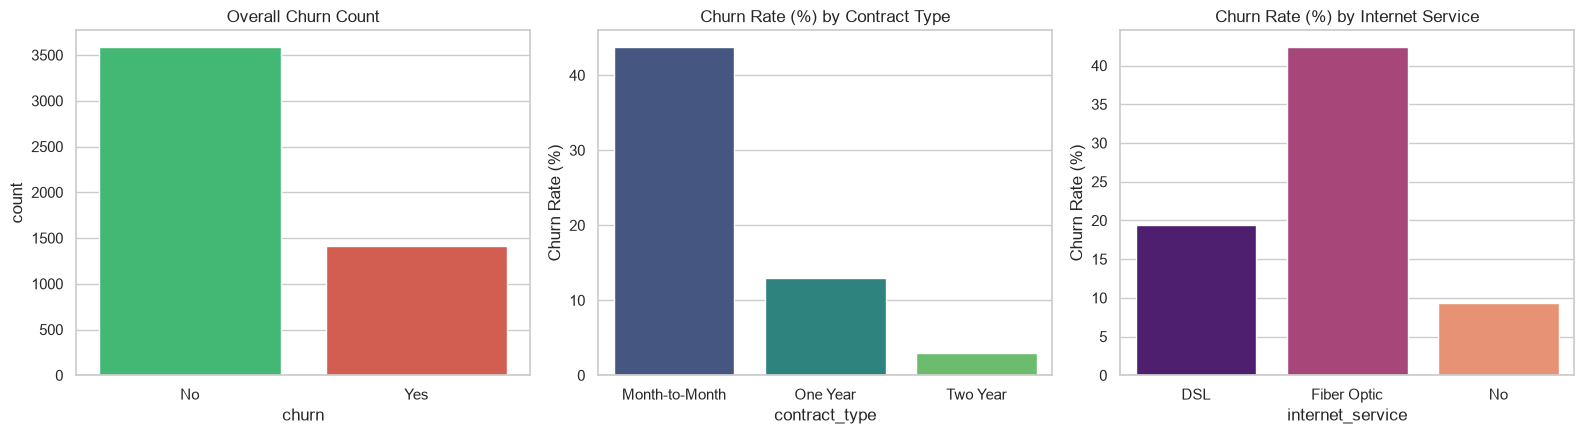

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Overall Churn Count
sns.countplot(
    data=clean_df,
    x="churn",
    hue="churn",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"},
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Overall Churn Count")

# 2. Churn Rate by Contract Type
contract_rates = (
    clean_df.groupby("contract_type", as_index=False)["churn_binary"].mean()
)
contract_rates["churn_pct"] = contract_rates["churn_binary"] * 100
sns.barplot(
    data=contract_rates,
    x="contract_type",
    y="churn_pct",
    hue="contract_type",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Churn Rate (%) by Contract Type")
axes[1].set_ylabel("Churn Rate (%)")

# 3. Churn Rate by Internet Service
internet_rates = (
    clean_df.groupby("internet_service", as_index=False)["churn_binary"].mean()
)
internet_rates["churn_pct"] = internet_rates["churn_binary"] * 100
sns.barplot(
    data=internet_rates,
    x="internet_service",
    y="churn_pct",
    hue="internet_service",
    palette="magma",
    legend=False,
    ax=axes[2],
)
axes[2].set_title("Churn Rate (%) by Internet Service")
axes[2].set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

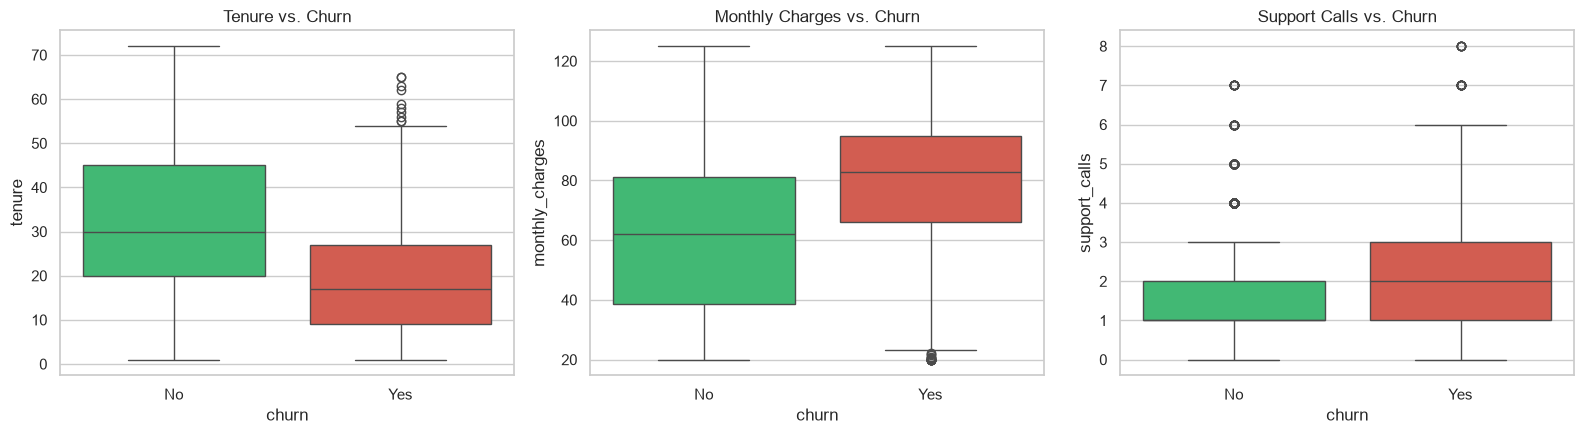

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(
    data=clean_df, x="churn", y="tenure", hue="churn",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}, legend=False, ax=axes[0]
)
axes[0].set_title("Tenure vs. Churn")

sns.boxplot(
    data=clean_df, x="churn", y="monthly_charges", hue="churn",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}, legend=False, ax=axes[1]
)
axes[1].set_title("Monthly Charges vs. Churn")

sns.boxplot(
    data=clean_df, x="churn", y="support_calls", hue="churn",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}, legend=False, ax=axes[2]
)
axes[2].set_title("Support Calls vs. Churn")

plt.tight_layout()
plt.show()

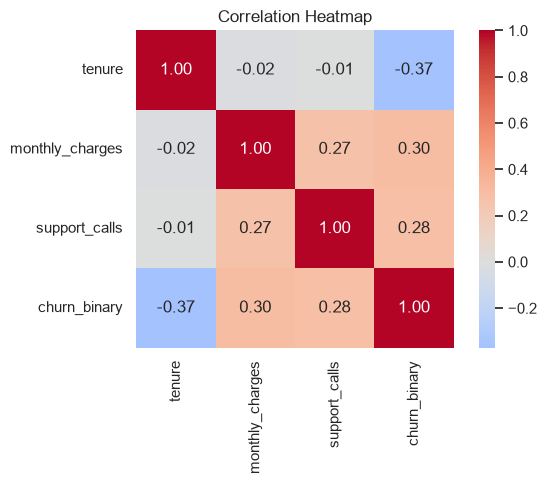

In [6]:
# Correlation Heatmap for Numeric Features + Binary Target
plt.figure(figsize=(6.5, 5))
corr_cols = ["tenure", "monthly_charges", "support_calls", "churn_binary"]
sns.heatmap(
    clean_df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Model Comparison: Logistic Regression vs. Random Forest
We use a `ColumnTransformer` inside a Scikit-Learn `Pipeline` to scale numeric features (`StandardScaler`) and one-hot encode categorical features (`OneHotEncoder`) without data leakage.

In [7]:
numeric_features = ["tenure", "monthly_charges", "support_calls"]
categorical_features = ["contract_type", "internet_service"]

X = clean_df[numeric_features + categorical_features]
y = clean_df["churn_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=4, random_state=42
    ),
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    trained_pipelines[name] = (pipe, y_pred)

    results.append(
        {
            "Model": name,
            "Accuracy": round(accuracy_score(y_test, y_pred), 4),
            "Precision": round(precision_score(y_test, y_pred), 4),
            "Recall": round(recall_score(y_test, y_pred), 4),
            "F1-Score": round(f1_score(y_test, y_pred), 4),
        }
    )

results_df = pd.DataFrame(results)
display(results_df)

C:\Users\SUPREME TRADERS\Desktop\Customer Churn & Sales Analytics Dashboard\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.817,0.7181,0.5780,0.6405
1,Random Forest,0.802,0.6810,0.5603,0.6148


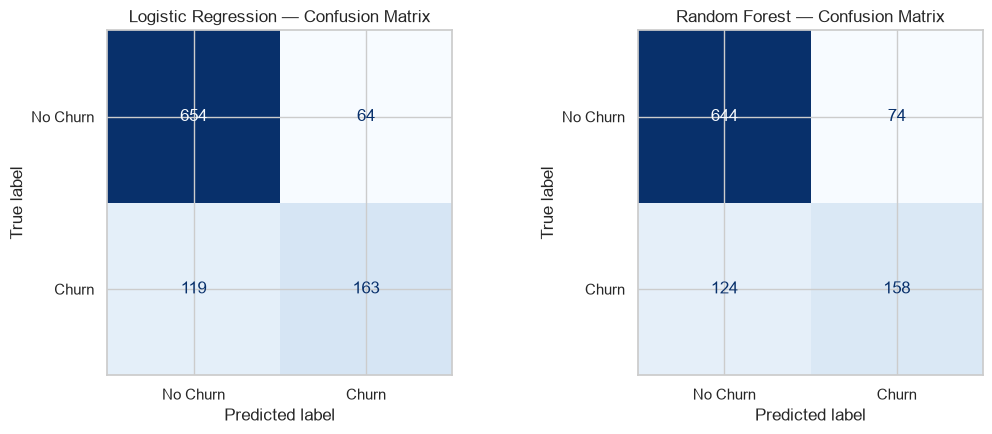

In [8]:
# Compare Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, (_, y_pred)) in zip(axes, trained_pipelines.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} — Confusion Matrix")

plt.tight_layout()
plt.show()

## 5. Key Takeaways for Stakeholders
- **Contract Type** is one of the strongest churn signals: Month-to-Month customers churn at a much higher rate than One Year or Two Year contract holders.
- **Support Calls** correlate strongly with churn — customers calling support frequently are much more likely to leave.
- **Tenure** is negatively correlated with churn — focusing retention outreach on customers in their first 12 months yields high impact.
- Both **Logistic Regression** and **Random Forest** perform strongly; Random Forest is saved via `src/train.py` for the interactive Streamlit dashboard because it naturally captures non-linear feature interactions.